# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


**Dataset:** The supplied `global_energy_mix.csv` contains 103 rows. All exercises have been executed using that dataset. Static chart images are saved below so they can be viewed without interactive JavaScript. The original CSV is embedded as a fallback for independent reruns.

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np
from pathlib import Path
from io import StringIO
import plotly.io as pio

# Embed Plotly.js in the notebook for interactive charts without a CDN.
pio.renderers.default = "notebook+plotly_mimetype"

# Use the original course layout, or place the CSV next to this notebook.
data_paths = [Path('../data/global_energy_mix.csv'),
              Path('data/global_energy_mix.csv'), Path('global_energy_mix.csv')]
data_path = next((path for path in data_paths if path.is_file()), None)
# Exact copy of the user-supplied CSV, used if no external CSV is present.
embedded_csv = 'Country,Region,Source,Share_pct,TWh\nUnited States,North America,Coal,10,1015.0\nUnited States,North America,Oil,35,3220.0\nUnited States,North America,Natural Gas,34,3083.0\nUnited States,North America,Nuclear,9,798.0\nUnited States,North America,Hydro,3,339.0\nUnited States,North America,Wind,4,413.0\nUnited States,North America,Solar,3,325.0\nUnited States,North America,Other Renewables,2,229.0\nChina,Asia,Coal,58,6929.1\nChina,Asia,Oil,18,1620.0\nChina,Asia,Natural Gas,10,872.0\nChina,Asia,Nuclear,4,394.0\nChina,Asia,Hydro,6,488.0\nChina,Asia,Wind,2,223.0\nChina,Asia,Solar,2,231.0\nGermany,Europe,Coal,5,537.0\nGermany,Europe,Oil,15,1361.0\nGermany,Europe,Natural Gas,27,2293.0\nGermany,Europe,Nuclear,5,476.0\nGermany,Europe,Hydro,4,453.0\nGermany,Europe,Wind,25,2348.0\nGermany,Europe,Solar,10,814.0\nGermany,Europe,Other Renewables,9,819.0\nFrance,Europe,Coal,1,120.0\nFrance,Europe,Oil,8,857.0\nFrance,Europe,Natural Gas,10,1160.0\nFrance,Europe,Nuclear,62,6882.0\nFrance,Europe,Hydro,7,711.0\nFrance,Europe,Wind,4,344.0\nFrance,Europe,Solar,4,376.0\nFrance,Europe,Other Renewables,4,413.0\nUnited Kingdom,Europe,Coal,2,230.0\nUnited Kingdom,Europe,Oil,25,2269.0\nUnited Kingdom,Europe,Natural Gas,37,3139.0\nUnited Kingdom,Europe,Nuclear,8,819.0\nUnited Kingdom,Europe,Hydro,2,174.0\nUnited Kingdom,Europe,Wind,17,1775.0\nUnited Kingdom,Europe,Solar,4,362.0\nUnited Kingdom,Europe,Other Renewables,5,446.0\nIndia,Asia,Coal,45,4319.0\nIndia,Asia,Oil,25,2593.0\nIndia,Asia,Natural Gas,10,1018.0\nIndia,Asia,Nuclear,2,180.0\nIndia,Asia,Hydro,10,1156.0\nIndia,Asia,Wind,5,422.0\nIndia,Asia,Solar,3,245.0\nBrazil,Latin America,Coal,3,312.0\nBrazil,Latin America,Oil,35,2973.0\nBrazil,Latin America,Natural Gas,9,902.0\nBrazil,Latin America,Nuclear,1,118.0\nBrazil,Latin America,Hydro,45,4857.0\nBrazil,Latin America,Wind,4,419.0\nBrazil,Latin America,Solar,2,206.0\nBrazil,Latin America,Other Renewables,1,87.0\nAustralia,Oceania,Coal,30,2919.0\nAustralia,Oceania,Oil,28,2624.0\nAustralia,Oceania,Natural Gas,22,2599.0\nAustralia,Oceania,Hydro,5,448.0\nAustralia,Oceania,Wind,10,989.0\nAustralia,Oceania,Solar,5,588.0\nJapan,Asia,Coal,30,3347.0\nJapan,Asia,Oil,25,2965.0\nJapan,Asia,Natural Gas,30,3130.0\nJapan,Asia,Nuclear,6,560.0\nJapan,Asia,Hydro,4,452.0\nJapan,Asia,Wind,3,275.0\nJapan,Asia,Solar,2,173.0\nSouth Korea,Asia,Coal,25,2706.0\nSouth Korea,Asia,Oil,22,2322.0\nSouth Korea,Asia,Natural Gas,28,3224.0\nSouth Korea,Asia,Nuclear,20,2370.0\nSouth Korea,Asia,Hydro,1,114.0\nSouth Korea,Asia,Wind,2,165.0\nSouth Korea,Asia,Solar,2,213.0\nNorway,Europe,Oil,20,2228.0\nNorway,Europe,Natural Gas,10,1193.0\nNorway,Europe,Hydro,65,6174.0\nNorway,Europe,Wind,3,260.0\nNorway,Europe,Solar,2,228.0\nSaudi Arabia,Middle East,Oil,55,5098.0\nSaudi Arabia,Middle East,Natural Gas,44,4573.0\nSaudi Arabia,Middle East,Wind,1,96.0\nSouth Africa,Africa,Coal,70,6727.0\nSouth Africa,Africa,Oil,13,1421.0\nSouth Africa,Africa,Natural Gas,5,472.0\nSouth Africa,Africa,Nuclear,3,323.0\nSouth Africa,Africa,Hydro,5,403.0\nSouth Africa,Africa,Wind,2,186.0\nSouth Africa,Africa,Solar,2,186.0\nCanada,North America,Coal,5,550.0\nCanada,North America,Oil,25,2315.0\nCanada,North America,Natural Gas,9,948.0\nCanada,North America,Nuclear,12,1290.0\nCanada,North America,Hydro,44,4679.0\nCanada,North America,Wind,3,312.0\nCanada,North America,Solar,2,193.0\nMexico,Latin America,Coal,10,949.0\nMexico,Latin America,Oil,40,4103.0\nMexico,Latin America,Natural Gas,38,3137.0\nMexico,Latin America,Nuclear,1,115.0\nMexico,Latin America,Hydro,7,791.0\nMexico,Latin America,Wind,2,188.0\nMexico,Latin America,Solar,2,205.0\n'
df = pd.read_csv(data_path) if data_path is not None else pd.read_csv(StringIO(embedded_csv))
required = {'Region', 'Country', 'Source', 'TWh'}
if not required.issubset(df.columns):
    raise ValueError(f'Missing columns: {sorted(required - set(df.columns))}')
df['TWh'] = pd.to_numeric(df['TWh'], errors='raise')
if df[list(required)].isna().any().any() or not np.isfinite(df['TWh']).all():
    raise ValueError('Region, Country, Source and TWh must contain valid, non-missing values.')
if (df['TWh'] < 0).any():
    raise ValueError('Energy values must be non-negative.')

# Use the source categories specified by the lecture.
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)
if df['Source_Type'].isna().any():
    raise ValueError('Unmapped energy sources: ' + ', '.join(
        sorted(df.loc[df['Source_Type'].isna(), 'Source'].unique())))

# Okabe–Ito colours: a colour-vision-deficiency-safe categorical palette.
fossil_colours = {'Coal': '#0072B2', 'Oil': '#E69F00', 'Natural Gas': '#009E73'}
parent_grey = '#D9D9D9'
px.defaults.template = 'plotly_white'

print(f'Loaded: {len(df)} rows')
print(df.head(10))

Loaded: 103 rows
         Country         Region  ...     TWh  Source_Type
0  United States  North America  ...  1015.0       Fossil
1  United States  North America  ...  3220.0       Fossil
2  United States  North America  ...  3083.0       Fossil
3  United States  North America  ...   798.0   Low-carbon
4  United States  North America  ...   339.0   Low-carbon
5  United States  North America  ...   413.0    Renewable
6  United States  North America  ...   325.0    Renewable
7  United States  North America  ...   229.0    Renewable
8          China           Asia  ...  6929.1       Fossil
9          China           Asia  ...  1620.0       Fossil

[10 rows x 6 columns]


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


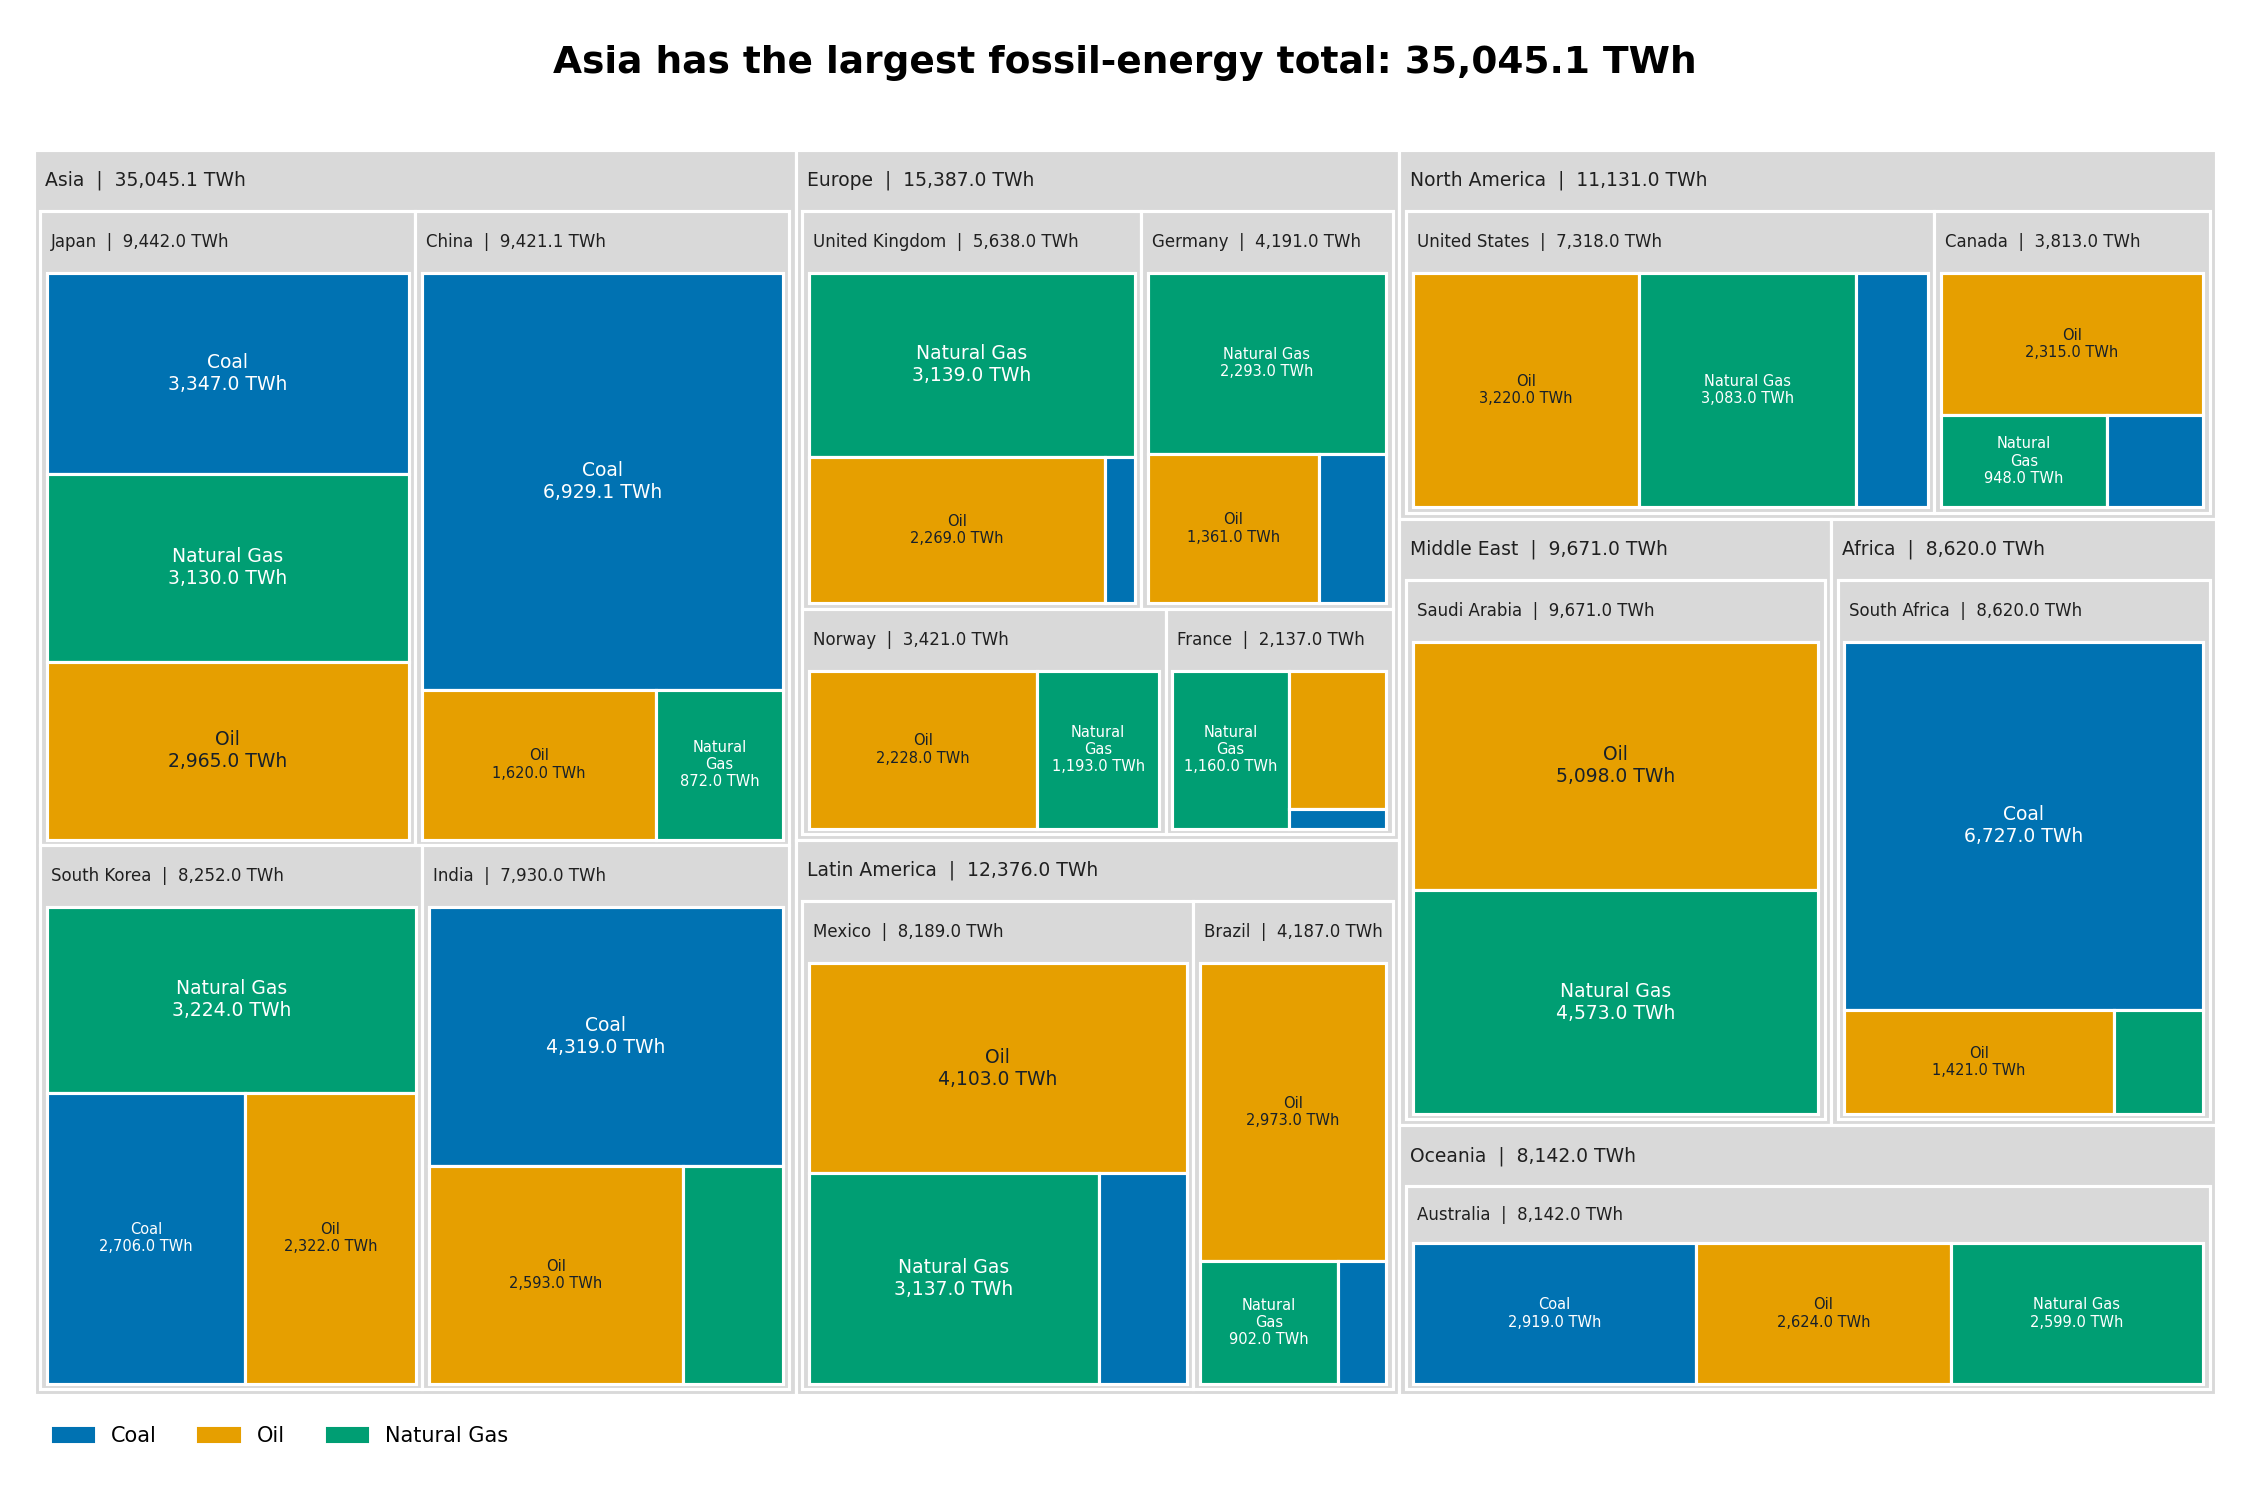

In [2]:
# Task 1 — absolute fossil energy by region, country and source.
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()
region_fossil = df_fossil.groupby('Region', observed=True)['TWh'].sum()
if region_fossil.empty or region_fossil.sum() <= 0:
    raise ValueError('Task 1 requires a positive fossil-energy total.')
leading_region = region_fossil.idxmax()

fig_fossil = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',
    color='Source',
    color_discrete_map=fossil_colours,
    title=(f'{leading_region} has the largest fossil-energy total: '
           f'{region_fossil[leading_region]:,.1f} TWh'),
)
# Plotly also creates region and country nodes; explicitly grey all parents.
trace = fig_fossil.data[0]
parent_ids = set(trace.parents) - {''}
trace.marker.colors = [
    parent_grey if node_id in parent_ids else fossil_colours[label]
    for node_id, label in zip(trace.ids, trace.labels)
]
fig_fossil.update_traces(
    texttemplate='%{label}<br>%{value:,.1f} TWh',
    hovertemplate='%{id}<br>%{value:,.1f} TWh<extra></extra>',
    marker_line=dict(color='white', width=1),
)
fig_fossil.update_layout(margin=dict(t=80, l=10, r=10, b=10))
fig_fossil.show()

# "Largest" means absolute fossil TWh here. This chart does not measure
# fossil energy as a share of each country's total energy supply.

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

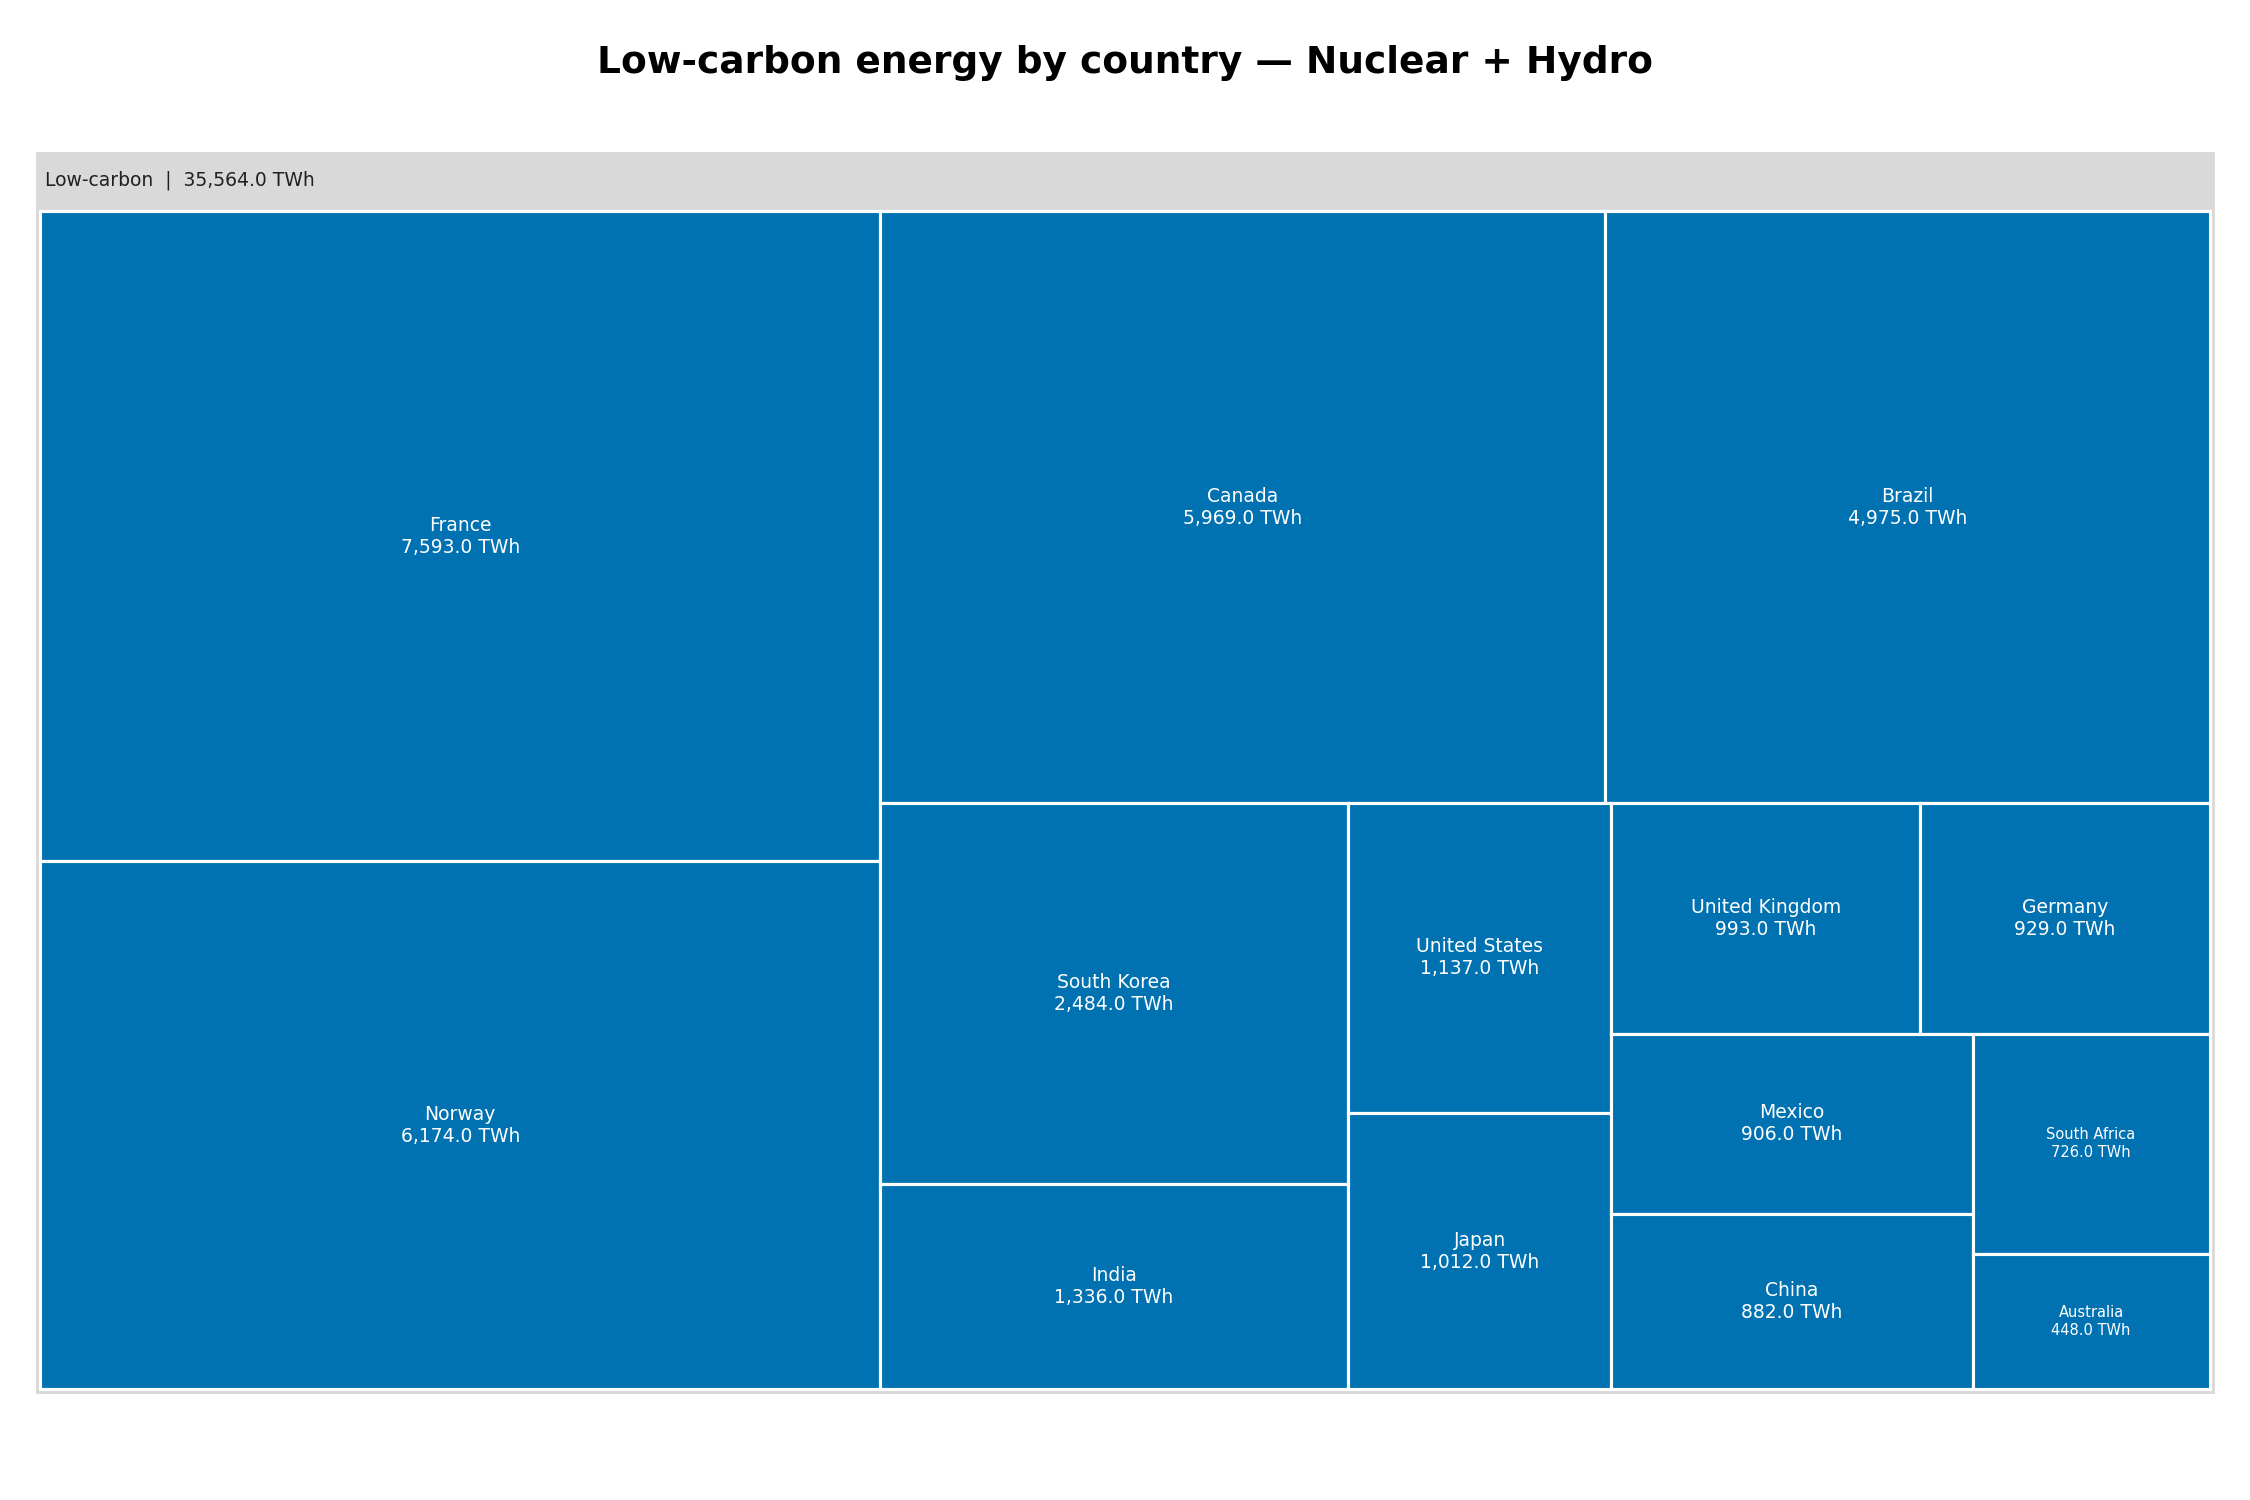

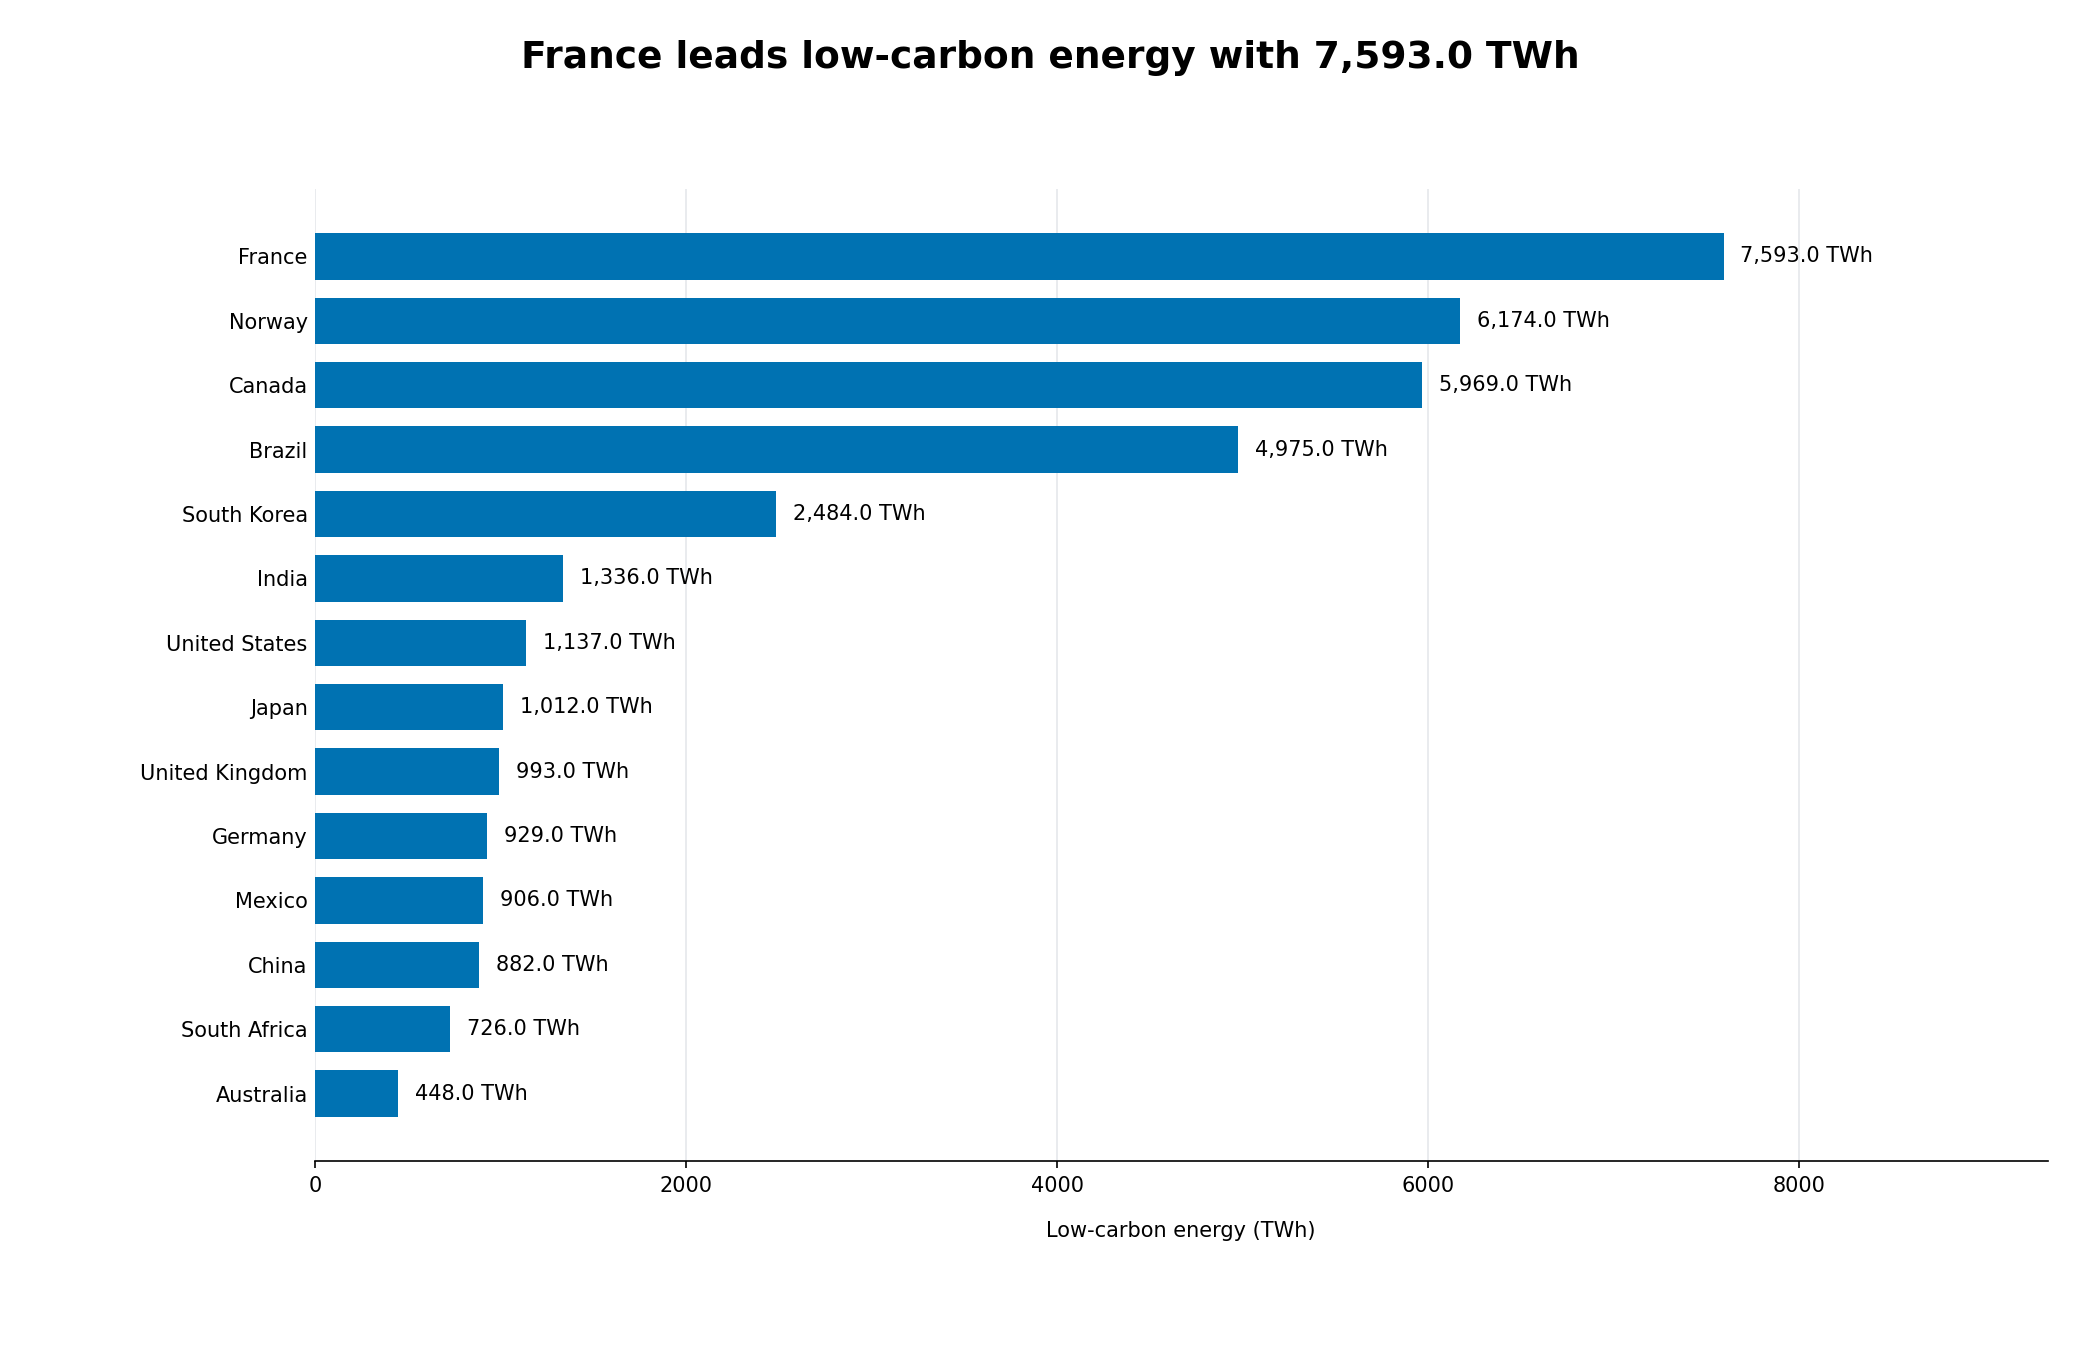

In [3]:
# Task 2 — Nuclear + Hydro, using the lecture's Low-carbon category.
low_carbon = (
    df.loc[df['Source_Type'] == 'Low-carbon']
      .groupby('Country', as_index=False, observed=True)['TWh'].sum()
      .sort_values(['TWh', 'Country'], ascending=[False, True])
      .reset_index(drop=True)
)
if low_carbon.empty or low_carbon['TWh'].sum() <= 0:
    raise ValueError('Task 2 requires a positive low-carbon-energy total.')
low_carbon['All'] = 'Low-carbon'
leading_country = low_carbon.iloc[0]['Country']
leading_twh = low_carbon.iloc[0]['TWh']

fig_low_tree = px.treemap(
    low_carbon, path=['All', 'Country'], values='TWh',
    title='Low-carbon energy by country — Nuclear + Hydro',
    color_discrete_sequence=['#0072B2'],
)
trace = fig_low_tree.data[0]
trace.marker.colors = [
    parent_grey if parent == '' else '#0072B2' for parent in trace.parents
]
fig_low_tree.update_traces(
    texttemplate='%{label}<br>%{value:,.1f} TWh',
    hovertemplate='%{label}<br>%{value:,.1f} TWh<extra></extra>',
    marker_line=dict(color='white', width=1),
)
fig_low_tree.show()

fig_low_bar = px.bar(
    low_carbon, x='TWh', y='Country', orientation='h', text='TWh',
    color_discrete_sequence=['#0072B2'],
    category_orders={'Country': low_carbon['Country'].tolist()},
    title=f'{leading_country} leads low-carbon energy with {leading_twh:,.1f} TWh',
    labels={'TWh': 'Low-carbon energy (TWh)'},
)
fig_low_bar.update_traces(
    texttemplate='%{x:,.1f} TWh', textposition='outside', cliponaxis=False,
    hovertemplate='%{y}<br>%{x:,.1f} TWh<extra></extra>',
)
fig_low_bar.update_layout(
    height=max(450, 32 * len(low_carbon) + 140),
    xaxis=dict(range=[0, leading_twh * 1.25]),
    yaxis_title=None, margin=dict(r=110),
    yaxis=dict(categoryorder='array', categoryarray=low_carbon['Country'].tolist(),
               autorange='reversed'),
)
fig_low_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The sorted horizontal bar chart communicates the ranking more clearly. All bars start at the same baseline, so their lengths can be compared accurately, and the largest total appears at the top. TWh labels also make close comparisons explicit. The treemap is useful for showing each country's contribution to the combined low-carbon total, but comparing rectangle areas is harder than comparing aligned lengths, especially when countries have similar totals.

In this dataset, France ranks first with **7,593.0 TWh**, followed by Norway (**6,174.0 TWh**) and Canada (**5,969.0 TWh**).

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

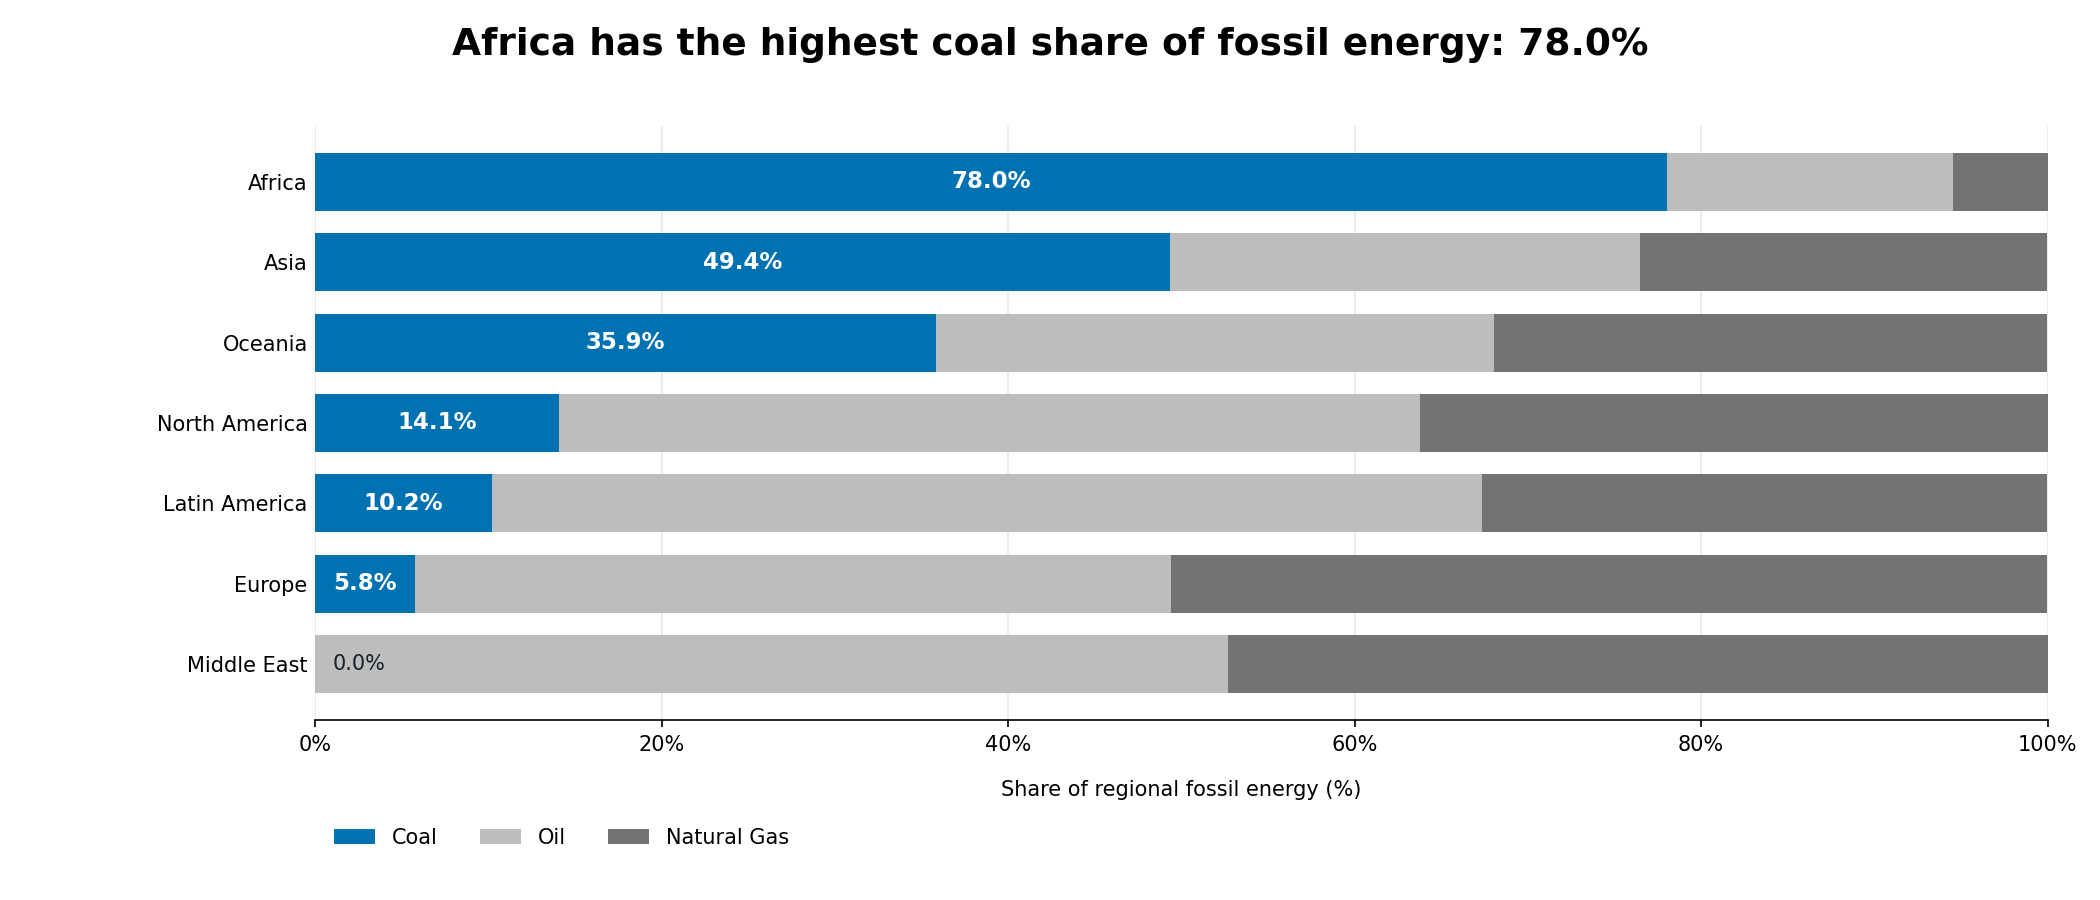

In [4]:
# Task 3 — each region's fossil mix, not its share of all energy.
source_order = ['Coal', 'Oil', 'Natural Gas']
regional_mix = (
    df_fossil.groupby(['Region', 'Source'], observed=True)['TWh'].sum()
    .unstack('Source', fill_value=0)
    .reindex(columns=source_order, fill_value=0)
)
# A region with zero fossil energy has no defined fossil mix.
regional_mix = regional_mix.loc[regional_mix.sum(axis=1) > 0]
regional_fossil = regional_mix.reset_index().melt(
    id_vars='Region', value_vars=source_order,
    var_name='Source', value_name='TWh',
)
regional_fossil['Fossil_Total_TWh'] = (
    regional_fossil.groupby('Region', observed=True)['TWh'].transform('sum')
)
regional_fossil['Share_pct'] = (
    100 * regional_fossil['TWh'] / regional_fossil['Fossil_Total_TWh']
)
coal_shares = (
    regional_fossil.loc[regional_fossil['Source'] == 'Coal']
    .sort_values(['Share_pct', 'Region'], ascending=[False, True])
)
region_order = coal_shares['Region'].tolist()
most_coal_region = coal_shares.iloc[0]['Region']
most_coal_share = coal_shares.iloc[0]['Share_pct']
regional_fossil['Coal_label'] = [
    f'{share:.1f}%' if source == 'Coal' else ''
    for source, share in zip(regional_fossil['Source'], regional_fossil['Share_pct'])
]

fig_mix = px.bar(
    regional_fossil, x='Share_pct', y='Region', color='Source',
    orientation='h', barmode='stack', text='Coal_label',
    category_orders={'Source': source_order, 'Region': region_order},
    color_discrete_map={
        'Coal': fossil_colours['Coal'], 'Oil': '#BDBDBD', 'Natural Gas': '#737373'
    },
    custom_data=['TWh', 'Fossil_Total_TWh'],
    title=(f'{most_coal_region} has the highest coal share of fossil energy: '
           f'{most_coal_share:.1f}%'),
    labels={'Share_pct': 'Share of regional fossil energy (%)', 'Source': 'Fossil source'},
)
fig_mix.update_traces(
    texttemplate='%{text}', textposition='inside', insidetextanchor='middle',
    hovertemplate=(
        '%{y}<br>%{fullData.name}: %{x:.1f}%'
        '<br>Source energy: %{customdata[0]:,.1f} TWh'
        '<br>Regional fossil total: %{customdata[1]:,.1f} TWh<extra></extra>'
    ),
)
fig_mix.update_layout(
    xaxis=dict(range=[0, 100], ticksuffix='%'), yaxis_title=None,
    yaxis=dict(categoryorder='array', categoryarray=region_order, autorange='reversed'),
    legend_title_text='Fossil source',
    height=max(400, 50 * len(region_order) + 150),
)
fig_mix.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Treemap:** Which country contributes the most fossil TWh within a region, and how does that country's total split across Coal, Oil and Natural Gas? The stacked bar aggregates countries, so it cannot show this country-level breakdown or compare their absolute energy totals.
- **100% stacked bar:** Which region has the highest coal share of its fossil energy, and how do the regions rank on that share? The common 0–100% scale and sorted coal segments answer this directly; the treemap encodes absolute TWh and does not directly display or rank these regional percentages. They could be calculated from its values, but they are not explicitly shown.

The stacked bars describe shares of **fossil energy**, not shares of each region's total energy. A region with a high coal share can still have a smaller absolute coal total than another region.

The computed results illustrate the distinction: **Asia** has the largest fossil total (**35,045.1 TWh**), while **Africa** has the highest coal share of fossil energy (**78.0%**).